# Exploración de Beijing
Usar Train para decidir preparación. Los resultados de Test sirven para evaluar decisiones ya fijadas, no para cambiarlas.

In [1]:
from pathlib import Path
import sys
BASE = Path.cwd() if (Path.cwd() / 'config.py').exists() else Path.cwd().parent
sys.path.insert(0, str(BASE))
import pandas as pd
import matplotlib.pyplot as plt
from config import configuracion, DATOS
from src.datos import cargar, auditar, particiones
c = configuracion()
particiones(c)

,bloque,inicio,fin_exclusivo,horas,porcentaje
0,train,2013-03-01,2015-12-19,24552,70.020534
1,val,2015-12-19,2016-07-25,5256,14.989733
2,test,2016-07-25,2017-03-01,5256,14.989733


## Auditoría por estación
Las banderas indican presencia original, no calidad instrumental. Ceros observados y faltantes son distintos.

In [2]:
auditoria = pd.concat([auditar(cargar(DATOS, s, c), s, c) for s in c['estaciones']])
auditoria.loc[auditoria.variable.isin(c['objetivos'])]

,estacion,bloque,variable,horas,observados,faltantes,ceros,negativos,minimo,p01,mediana,p99,maximo,media,mayor_racha_faltante
0,Aotizhongxin,train,pm25,24552,23822,730,0,0,3.0000,3.0,61.0,351.79,665.0,83.641059,343
1,Aotizhongxin,train,ozone,24552,23145,1407,0,0,0.2142,1.0,40.0,245.56,423.0,55.300183,343
11,Aotizhongxin,val,pm25,5256,5148,108,0,0,3.0000,4.0,48.0,433.53,898.0,74.563131,28
12,Aotizhongxin,val,ozone,5256,5096,160,0,0,2.0000,2.0,61.0,261.05,342.0,72.193485,3
22,Aotizhongxin,test,pm25,5256,5169,87,0,0,3.0000,3.0,55.0,426.32,713.0,86.952989,25
23,Aotizhongxin,test,ozone,5256,5104,152,0,0,2.0000,2.0,31.0,220.97,350.0,45.313871,25
0,Changping,train,pm25,24552,23908,644,0,0,2.0000,3.0,49.0,313.00,581.0,72.886866,167
1,Changping,train,ozone,24552,24067,485,0,0,0.2142,2.0,49.0,253.00,429.0,61.500540,64
11,Changping,val,pm25,5256,5185,71,0,0,3.0000,3.0,39.0,317.64,882.0,60.573770,4
12,Changping,val,ozone,5256,5196,60,0,0,2.0000,2.0,52.0,242.00,327.0,61.816975,4


## Evolución y ciclo horario en Train
Los promedios siguientes son exploratorios; no sustituyen las etiquetas horarias de evaluación.

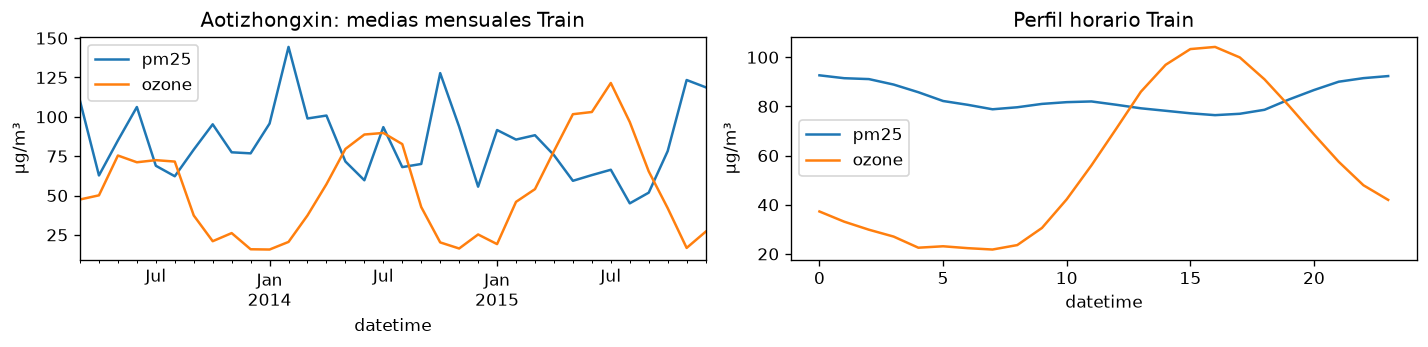

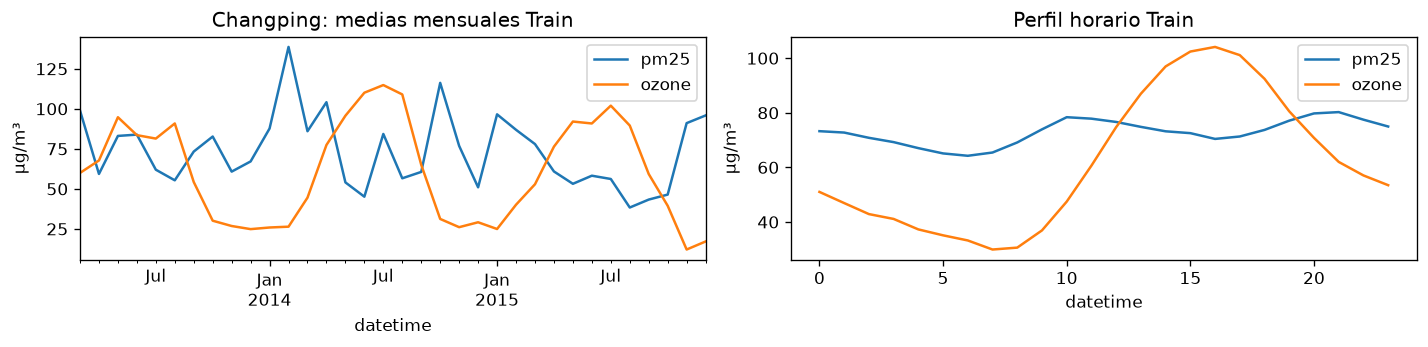

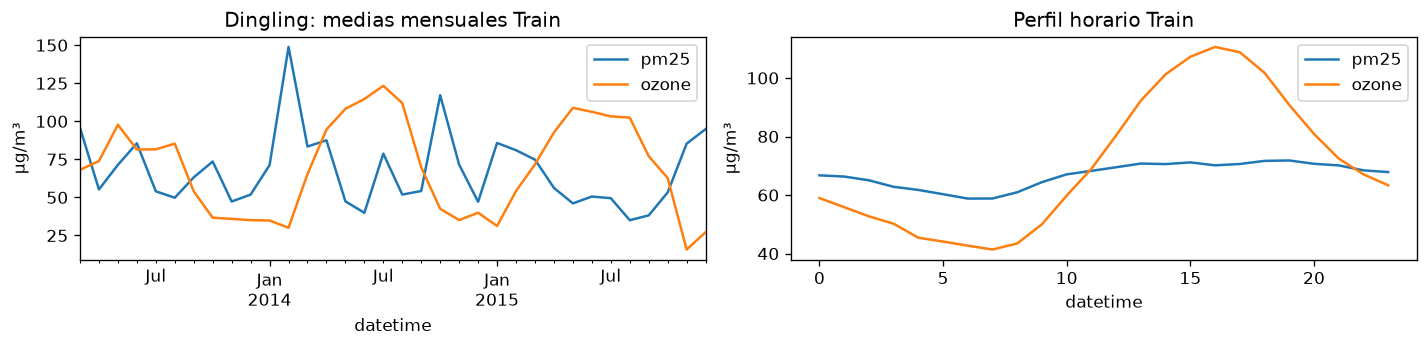

In [3]:
for s in c['estaciones']:
    df = cargar(DATOS, s, c)
    train = df.loc[df.index < c['inicio_val']]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    train[c['objetivos']].resample('MS').mean().plot(ax=axes[0], title=s + ': medias mensuales Train')
    train[c['objetivos']].groupby(train.index.hour).mean().plot(ax=axes[1], title='Perfil horario Train')
    for ax in axes: ax.set_ylabel('µg/m³')
    plt.tight_layout()
    plt.show()

## Comparación ejecutada
Cada fila conserva la semilla. No seleccionar retrospectivamente el mejor Test. Consultar inventario para distinguir resultados parciales.

In [4]:
out = BASE / 'resultados'
print((out / 'metricas/inventario.json').read_text())
metricas = pd.read_csv(out / 'metricas/comparacion.csv')
metricas

{
  "casos": 6,
  "referencias_naive": 12,
  "ajustes_sarima": 6,
  "entrenamientos_lstm": 24,
  "filas_prediccion": 441504,
  "comparabilidad_verificada": true
}


,estacion,objetivo,modelo,variante,ejecucion,bloque,n_observados,n_total,cobertura,MAE,RMSE,negativos_pred,principal
0,Aotizhongxin,ozone,LSTM,base,2026,test,5104,5256,0.971081,23.687290,32.100714,5,False
1,Aotizhongxin,ozone,LSTM,base,2026,val,5096,5256,0.969559,26.838180,35.029755,0,False
2,Aotizhongxin,ozone,LSTM,meteo,2026,test,5104,5256,0.971081,23.369783,31.388553,65,True
3,Aotizhongxin,ozone,LSTM,meteo,2026,val,5096,5256,0.969559,26.274050,34.486692,13,True
4,Aotizhongxin,ozone,LSTM,meteo,2027,test,5104,5256,0.971081,23.633151,31.557832,66,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,Dingling,pm25,Naive,168,sin_ajuste,val,5153,5256,0.980403,69.244518,107.817882,0,False
80,Dingling,pm25,Naive,24,sin_ajuste,test,5041,5256,0.959094,55.442174,82.414296,0,False
81,Dingling,pm25,Naive,24,sin_ajuste,val,5153,5256,0.980403,49.794683,85.605547,0,False
82,Dingling,pm25,SARIMA,estacional24,unico,test,5041,5256,0.959094,36.675724,58.045617,0,False


In [5]:
pd.read_csv(out / 'metricas/variabilidad.csv')

,estacion,objetivo,variante,bloque,semillas,MAE_media,MAE_std,MAE_min,MAE_max,RMSE_media,RMSE_std
0,Aotizhongxin,ozone,meteo,test,3,23.498663,0.131774,23.369783,23.633151,31.508486,0.104406
1,Aotizhongxin,ozone,meteo,val,3,26.352107,0.093222,26.274050,26.455327,34.793835,0.374921
2,Aotizhongxin,pm25,base,test,3,43.948657,0.151395,43.793020,44.095419,66.678487,0.184250
3,Aotizhongxin,pm25,base,val,3,40.227729,0.629146,39.615705,40.872703,63.586424,0.413762
4,Changping,ozone,meteo,test,3,20.366072,0.128214,20.225906,20.477434,27.050993,0.078043
5,Changping,ozone,meteo,val,3,23.355802,0.220663,23.119170,23.555949,31.271172,0.239970
6,Changping,pm25,base,test,3,39.059368,0.909735,38.192941,40.006970,62.096540,0.368055
7,Changping,pm25,base,val,3,32.967829,1.253275,32.007489,34.385554,51.294708,0.513044
8,Dingling,ozone,meteo,test,3,22.523426,0.481316,22.071222,23.029348,29.561680,0.483272
9,Dingling,ozone,meteo,val,3,25.286350,0.557813,24.649240,25.686905,34.526876,0.593869
